# Validação de ponta a ponta · US09 — relatório automático de desvios

Este notebook percorre, **etapa por etapa**, o que o relatório da US09 faz e mostra a saída real de cada uma.
No fim, confere os 6 itens do DoD automaticamente e mostra um **esboço do relatório final** (a página HTML).

| Etapa | O que mostra |
| --- | --- |
| 0 | Preparação e ambiente |
| 1 | Entradas: o que a US06 (pose) e a US07 (áreas) entregam |
| 2 | Padrão esperado e desvios detectados (US08) |
| 3 | Confiança de cada desvio |
| 4 | Resumo: total por tipo e % do tempo em desvio |
| 5 | Publicação e alerta de severidade alta (US19) |
| 6 | O relatório em JSON |
| 7 | O relatório em HTML |
| 8 | O mesmo resultado com o comando único (`gerar`) |
| 9 | Casos de borda: vídeo sem desvios |
| 10 | Privacidade: nada de dado pessoal |
| 11 | **Checklist do DoD** (✔/✘ automático) |
| 12 | Dados reais do repositório |
| 13 | Rode com os seus arquivos (opcional) |
| 14 | **Esboço do resultado final** |

**Os dados são sintéticos** (um vídeo com uma queda aos 4 s e uma pessoa na borda do leito), gerados aqui mesmo.
Nada é enviado para a internet e nada fora de `saida/validacao_us09/` é alterado.

## Antes de começar

1. Escolha como kernel o Python do `.venv` do projeto (o criado com `pip install -r video/requirements.txt`).
2. Se o kernel pedir, instale o que só o notebook usa: `.venv\Scripts\python -m pip install ipykernel matplotlib`.
3. Rode tudo (**Run All**). Dá para rodar célula a célula; as etapas dependem das anteriores.

Se alguma célula falhar, o erro aparece na própria célula; o checklist da etapa 11 diz o que ficou sem validar.

## Etapa 0 · Preparação

**O que acontece:** acha a raiz do projeto, cria a pasta de saída e define uma `PSEUDONYM_KEY` **de teste** só para este kernel
(o seu `.env` não é lido nem alterado).

In [5]:
import html
import json
import os
import shutil
import subprocess
import sys
import time
from pathlib import Path

os.environ.setdefault("OPENCV_LOG_LEVEL", "ERROR")  # silencia avisos do OpenCV nas saídas

def achar_raiz():
    for pasta in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (pasta / "pyproject.toml").is_file() and (pasta / "video" / "relatorio").is_dir():
            return pasta
    raise RuntimeError("Abra este notebook dentro do repositório (não achei pyproject.toml e video/relatorio).")

RAIZ = achar_raiz()
sys.path.insert(0, str(RAIZ))
os.chdir(RAIZ)  # como no uso real: as saídas e os URIs dos quadros de evidência são relativos à raiz

CHAVE_DE_TESTE = "chave-de-teste-com-mais-de-32-bytes-000000"
os.environ["PSEUDONYM_KEY"] = CHAVE_DE_TESTE  # vale só neste kernel

BASE = Path("saida/validacao_us09")   # tudo que o notebook grava fica aqui (saida/ não é versionada)
BASE.mkdir(parents=True, exist_ok=True)
for antiga in BASE.iterdir():         # limpa execuções anteriores; se o Windows/OneDrive segurar algum arquivo, ele só fica lá
    shutil.rmtree(antiga, ignore_errors=True)
DESTINO = BASE / time.strftime("%Y%m%d-%H%M%S")   # uma pasta nova por execução: nunca esbarra em restos da anterior
DESTINO.mkdir()
print("pasta do projeto:", RAIZ.name)
print("saídas deste notebook em:", DESTINO.as_posix())

pasta do projeto: monitoramento-medico-multimodal
saídas deste notebook em: saida/validacao_us09/20261112-225602


In [7]:
from datetime import UTC, datetime, timedelta

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydantic
from IPython.display import HTML, display
from IPython.display import Image as Imagem

from contratos import (
    BarramentoLocal,
    EmissorJsonl,
    EventoAchado,
    Evidencia,
    Modalidade,
    Severidade,
    agora_utc,
    pseudonimizar_paciente,
)
from video import criar_video_teste
from video.desvios.config import carregar_config as carregar_config_desvios
from video.desvios.regras import serie_quadril
from video.desvios.run import executar
from video.pose.sequence import PoseFrame, PoseSequence
from video.relatorio import MODEL_VERSION, SCHEMA_VERSION, confianca, construcao, privacidade, tempo
from video.relatorio.config import carregar_config as carregar_config_relatorio
from video.relatorio.html import embutir_imagens, renderizar
from video.relatorio.run import gerar, publicar

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
print(f"OpenCV {cv2.__version__} | numpy {np.__version__} | pandas {pd.__version__} | pydantic {pydantic.__version__}")
print("relatório:", MODEL_VERSION, "| esquema", SCHEMA_VERSION)

ModuleNotFoundError: No module named 'cv2'

## Etapa 1 · Entradas: o que a US06 e a US07 entregam

**O que acontece:** a US09 não extrai pose nem detecta objetos; ela lê o que as etapas anteriores gravam.
Aqui montamos, de forma sintética, os mesmos arquivos:

- **US06 (OpenPose):** um JSON com os keypoints `[x, y, confiança]` de cada quadro. A pessoa fica em pé até 4 s, cai e permanece no chão até os 12 s.
- **US07 (YOLOv8):** eventos de entrada e saída da área crítica `borda_leito` (de 2,0 s a 6,5 s).

**O que conferir:** o vídeo tem 12 s; a pose tem 120 quadros; os eventos da US07 trazem a confiança da detecção e a versão do YOLOv8.

In [3]:
PACIENTE = pseudonimizar_paciente(10000032, chave=CHAVE_DE_TESTE)   # o ID de origem nunca aparece nos arquivos
INICIO = datetime(2026, 10, 5, 19, 0, tzinfo=UTC)
FPS = 10.0

def corpo(quadril_y, *, x=300.0, conf=0.9):
    pescoco_y = quadril_y - 100
    return {
        "Neck": [x, pescoco_y, conf], "MidHip": [x, quadril_y, conf],
        "LHip": [x - 10, quadril_y, conf], "RHip": [x + 10, quadril_y, conf],
        "LKnee": [x - 10, quadril_y + 50, conf], "RKnee": [x + 10, quadril_y + 50, conf],
        "LAnkle": [x - 10, quadril_y + 100, conf], "RAnkle": [x + 10, quadril_y + 100, conf],
        "LShoulder": [x - 20, pescoco_y, conf], "RShoulder": [x + 20, pescoco_y, conf],
    }

def montar_pose(corpos, video, fps=FPS):
    return PoseSequence(
        video_id="sintetico", source_path=str(video), keypoint_names=sorted(corpos[0]),
        metadata={"min_valid_keypoints": 8, "model": "BODY_25", "module_version": "0.1.0",
                  "source_fps": fps, "processed_fps": fps},
        frames=[PoseFrame(i, round(1000 * i / fps), kp) for i, kp in enumerate(corpos)])

def evento_area(tipo, t, *, area="borda_leito", score=0.8):
    return EventoAchado.criar(
        patient_id=PACIENTE, modality=Modalidade.VIDEO, event_type=tipo,
        timestamp=INICIO + timedelta(seconds=t), score=score, severity=Severidade.BAIXA,
        evidence=Evidencia(
            summary=f"person {tipo}",
            features={"classe": "person", "area_critica_id": area, "area_critica_nome": area.replace("_", " ").capitalize(),
                      "tempo_video_s": t, "frame_index": int(t * FPS), "x1": 10.0, "y1": 10.0, "x2": 50.0, "y2": 90.0, "track_id": 3},
            thresholds={"confianca_minima": 0.25, "iou_nms": 0.5, "criterio_roi": "fracao"},
            models={"yolov8": "yolov8n@8.4.173"}),
        model_version="video-areas-criticas@0.1.0")

alturas = [200.0] * 40 + [230, 270, 310, 320] + [320.0] * 76   # em pé até 4 s, cai e fica no chão até 12 s
video = criar_video_teste(DESTINO / "leito.avi", quadros=len(alturas), fps=FPS, largura=640, altura=480)
pose = montar_pose([corpo(y) for y in alturas], video)
pose.save_json(DESTINO / "leito.json")
EmissorJsonl(DESTINO / "areas.jsonl").emitir_varios([
    evento_area("entrada_area_critica", 2.0),
    evento_area("saida_area_critica", 6.5, score=0.62),
])

print(f"vídeo sintético: {len(alturas)} quadros a {FPS:g} quadros/s = {len(alturas) / FPS:g} s")
print(f"pose (US06): {len(pose.frames)} quadros, {len(pose.keypoint_names)} keypoints por quadro, modelo {pose.metadata['model']}")
print("\num quadro da pose (keypoint = [x, y, confiança]), o quadro 43, em plena queda:")
print(json.dumps({k: pose.frames[43].keypoints[k] for k in ("Neck", "MidHip", "RKnee")}, indent=2))

linhas = [EventoAchado.de_json(linha) for linha in (DESTINO / "areas.jsonl").read_text(encoding="utf-8").splitlines()]
print("\neventos da US07 (YOLOv8):")
display(pd.DataFrame([{
    "evento": e.event_type, "t no vídeo (s)": e.evidence.features["tempo_video_s"],
    "confiança da detecção": e.score, "área": e.evidence.features["area_critica_id"],
    "modelo": e.evidence.models["yolov8"]} for e in linhas]))

vídeo sintético: 120 quadros a 10 quadros/s = 12 s
pose (US06): 120 quadros, 10 keypoints por quadro, modelo BODY_25

um quadro da pose (keypoint = [x, y, confiança]), o quadro 43, em plena queda:
{
  "Neck": [
    300.0,
    220,
    0.9
  ],
  "MidHip": [
    300.0,
    320,
    0.9
  ],
  "RKnee": [
    310.0,
    370,
    0.9
  ]
}

eventos da US07 (YOLOv8):


,evento,t no vídeo (s),confiança da detecção,área,modelo
0,entrada_area_critica,2.0,0.80,borda_leito,yolov8n@8.4.173
1,saida_area_critica,6.5,0.62,borda_leito,yolov8n@8.4.173


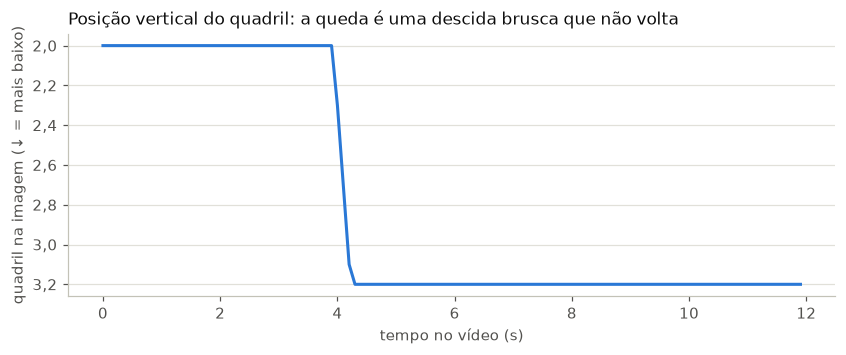

In [4]:
# O sinal que a regra de queda observa: a altura do quadril, em comprimentos de tronco
tempos, y_quadril, escala = serie_quadril(pose)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110})
fig, ax = plt.subplots(figsize=(9, 3.1))
ax.plot(tempos, y_quadril, color="#2a78d6", linewidth=2)
ax.invert_yaxis()   # y cresce para baixo na imagem: aqui, "mais baixo" fica embaixo
ax.set_xlabel("tempo no vídeo (s)")
ax.set_ylabel("quadril na imagem (↓ = mais baixo)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))   # vírgula, como no relatório
ax.set_title("Posição vertical do quadril: a queda é uma descida brusca que não volta", loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
plt.show()

## Etapa 2 · Padrão esperado e desvios detectados (US08)

**O que acontece:** o perfil `internacao_leito` define o padrão esperado (sem queda, sem giro brusco, ninguém na borda do leito por mais de 3 s).
A US08 aplica esse padrão à pose e aos eventos da US07 e devolve os desvios que persistiram pela janela mínima.

**O que conferir:** a queda aos ~4 s (severidade **alta**) e a presença na borda do leito por 4,5 s (severidade **média**), cada uma com um quadro de evidência anonimizado.

In [5]:
cfg_desvios = carregar_config_desvios("config/us08_padroes.yaml")
perfil = cfg_desvios.perfil("internacao_leito")
print("versão dos limiares:", cfg_desvios.versao)
print("padrão esperado:   ", perfil.descricao)
display(pd.DataFrame(
    [{"regra": "queda", "limiar": f"{perfil.queda.limiar:g} comprimentos de tronco", "tempo máx. do movimento (s)": perfil.queda.tempo_max_s,
      "persistência mínima (s)": perfil.queda.janela_s, "severidade": perfil.queda.severidade.value},
     {"regra": "mudança brusca", "limiar": f"{perfil.mudanca_brusca.limiar:g}°", "tempo máx. do movimento (s)": perfil.mudanca_brusca.tempo_max_s,
      "persistência mínima (s)": perfil.mudanca_brusca.janela_s, "severidade": perfil.mudanca_brusca.severidade.value}]
    + [{"regra": f"área {a.area_id}", "limiar": f"classes {sorted(a.classes_proibidas)}", "tempo máx. do movimento (s)": None,
        "persistência mínima (s)": a.janela_s, "severidade": a.severidade.value} for a in perfil.areas]))

versão dos limiares: 1.2.0
padrão esperado:    Paciente internado, câmera no leito. Padrão: paciente deitado ou sentado no leito, sem quedas e sem permanecer na borda do colchão (risco de queda).


,regra,limiar,tempo máx. do movimento (s),persistência mínima (s),severidade
0,queda,0.7 comprimentos de tronco,1.0,0.5,alta
1,mudança brusca,60°,0.5,0.5,media
2,área borda_leito,classes ['person'],NaN,3.0,media
3,área lateral_leito,classes ['person'],NaN,3.0,baixa


In [6]:
execucao = executar(
    perfil_id="internacao_leito", config=Path("config/us08_padroes.yaml"),
    pose_path=DESTINO / "leito.json", eventos_areas_path=DESTINO / "areas.jsonl",
    patient_id=PACIENTE, inicio_utc="2026-10-05T19:00:00Z",
    saida=DESTINO / "etapas", pose_config=Path("video/pose/config.yaml"))

res = execucao.resultado
print(f"duração {res.duracao_s:g} s | quadros analisados {res.quadros} | pessoa detectada em {res.cobertura_pct}% dos quadros | análise confiável: {res.confiavel}")
display(pd.DataFrame([{
    "tipo": d.event_type, "regra": d.regra, "severidade": d.severidade.value, "início (s)": round(d.inicio_s, 2),
    "fim (s)": round(d.fim_s, 2), "frame de evidência": d.frame_idx, "valor": d.valor, "limiar": d.limiar,
    "unidade": d.unidade, "score (intensidade)": d.score} for d in res.desvios]))
print("\nresumo em português de cada desvio:")
for d in res.desvios:
    print(f" - [{d.severidade.value}] {d.resumo}")

duração 12 s | quadros analisados 120 | pessoa detectada em 100.0% dos quadros | análise confiável: True


,tipo,regra,severidade,início (s),fim (s),frame de evidência,valor,limiar,unidade,score (intensidade)
0,presenca_indevida_area_critica,area.borda_leito,media,2.0,6.5,20,4.5,3.0,segundos,0.71
1,mudanca_brusca_ou_queda,queda,alta,3.1,12.0,43,1.2,0.7,comprimentos de tronco,0.75



resumo em português de cada desvio:
 - [media] person permaneceu na área crítica 'Borda leito' por 4,5 s (de 2,0 s até 6,5 s), acima do tolerado de 3,0 s.
 - [alta] Possível queda aos 4,1 s: o quadril desceu 1,2 comprimentos de tronco em 1,0 s e ficou embaixo por 7,9 s.


quadros de evidência (anonimizados: a cabeça é tarjada; a legenda diz a regra, o instante e a medida):

presenca_indevida_area_critica → saida/validacao_us09/20261112-224122/etapas/sintetico/00_area.borda_leito_0002.00s.jpg


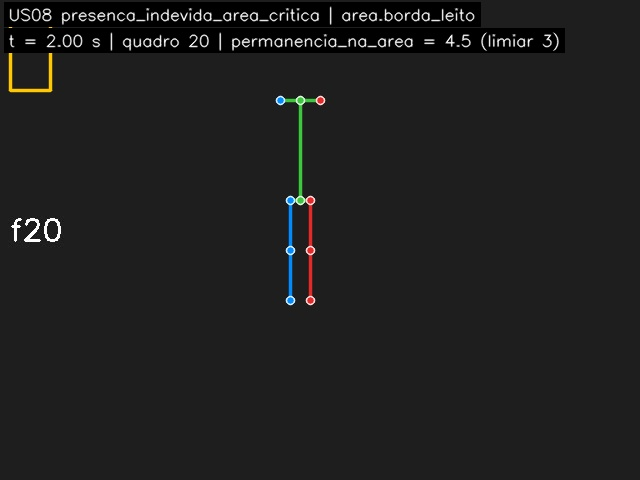

mudanca_brusca_ou_queda → saida/validacao_us09/20261112-224122/etapas/sintetico/01_queda_0004.30s.jpg


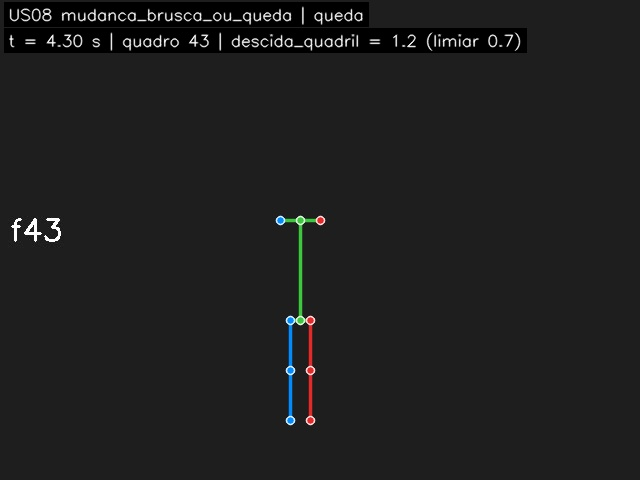

In [7]:
print("quadros de evidência (anonimizados: a cabeça é tarjada; a legenda diz a regra, o instante e a medida):\n")
for evento in execucao.eventos:
    for artefato in evento.evidence.artifacts:
        print(f"{evento.event_type} → {artefato.uri}")
        display(Imagem(filename=artefato.uri, width=460))

## Etapa 3 · Confiança de cada desvio

**O que acontece:** o `score` do evento mede a **intensidade** do desvio (0,5 ao passar o limiar, 1,0 na saturação), não a certeza de que ele existe.
A confiança vem da fonte da regra: **keypoints do OpenPose** (regras de pose) ou **detecção do YOLOv8** (regras de área).

**O que conferir:** a queda tem confiança 0,90 (os keypoints do tronco foram vistos com 0,9); a presença na área tem 0,71 (média de 0,80 e 0,62 da US07).
Na segunda tabela, a mesma queda com keypoints de confiança 0,35 é marcada como **baixa confiança**.

In [8]:
cfg_rel = carregar_config_relatorio("config/us09_relatorio.yaml")
print(f"critérios (config/us09_relatorio.yaml v{cfg_rel.versao}): confiança mínima {cfg_rel.confianca.minima} | cobertura mínima {cfg_rel.confianca.cobertura_minima_pct}%\n")

linhas = []
for d in res.desvios:
    c = confianca.avaliar(d, execucao.pose, cfg_rel.confianca)
    linhas.append({"desvio": d.event_type, "regra": d.regra, "score do evento": d.score, "confiança": c.valor,
                   "cobertura do trecho (%)": c.cobertura_pct, "baixa confiança?": c.baixa, "origem da confiança": c.origem})
display(pd.DataFrame(linhas))

print("\nA mesma queda, se o OpenPose tivesse visto o corpo com confiança 0,35:")
queda = next(d for d in res.desvios if d.regra == "queda")
c_ruim = confianca.da_pose(queda, montar_pose([corpo(y, conf=0.35) for y in alturas], video), cfg_rel.confianca)
display(pd.DataFrame([{"confiança": c_ruim.valor, "cobertura (%)": c_ruim.cobertura_pct, "baixa confiança?": c_ruim.baixa}]))

critérios (config/us09_relatorio.yaml v1.0.0): confiança mínima 0.5 | cobertura mínima 50.0%



,desvio,regra,score do evento,confiança,cobertura do trecho (%),baixa confiança?,origem da confiança
0,presenca_indevida_area_critica,area.borda_leito,0.71,0.71,NaN,False,YOLOv8: média da confiança da detecção na entrada e na saída da área
1,mudanca_brusca_ou_queda,queda,0.75,0.90,100.0,False,OpenPose: média da confiança dos keypoints da medida nos quadros do trecho



A mesma queda, se o OpenPose tivesse visto o corpo com confiança 0,35:


,confiança,cobertura (%),baixa confiança?
0,0.35,100.0,True


## Etapa 4 · Resumo: total por tipo e % do tempo em desvio

**O que acontece:** a queda e a presença na borda do leito **acontecem ao mesmo tempo**. Somar as durações contaria esse trecho duas vezes;
por isso o relatório **une** os intervalos antes de calcular o percentual.

**O que conferir:** a soma ingênua passa de 100% do vídeo (impossível); a união dá o valor correto.

In [9]:
desvios = res.desvios
duracao = res.duracao_s
intervalos = [(d.inicio_s, d.fim_s) for d in desvios]
unidos = tempo.unir(intervalos, limite=duracao)
soma_ingenua = sum(fim - ini for ini, fim in intervalos)
em_desvio = tempo.total(unidos)

display(pd.DataFrame([{"desvio": d.event_type, "início (s)": round(d.inicio_s, 2), "fim (s)": round(d.fim_s, 2),
                       "duração (s)": round(d.duracao_s, 2)} for d in desvios]))
print(f"soma ingênua das durações : {soma_ingenua:5.1f} s = {100 * soma_ingenua / duracao:6.1f}% do vídeo   <- passa de 100%, não pode")
print(f"união dos intervalos      : {[(round(i, 2), round(f, 2)) for i, f in unidos]}")
print(f"tempo em desvio (união)   : {em_desvio:5.1f} s = {tempo.percentual(em_desvio, duracao):6.2f}% do vídeo")
assert soma_ingenua > duracao and tempo.percentual(em_desvio, duracao) <= 100

,desvio,início (s),fim (s),duração (s)
0,presenca_indevida_area_critica,2.0,6.5,4.5
1,mudanca_brusca_ou_queda,3.1,12.0,8.9


soma ingênua das durações :  13.4 s =  111.7% do vídeo   <- passa de 100%, não pode
união dos intervalos      : [(2.0, 12.0)]
tempo em desvio (união)   :  10.0 s =  83.33% do vídeo


## Etapa 5 · Publicação e alerta de severidade alta (US19)

**O que acontece:** os eventos do vídeo vão ao barramento. O motor de alertas da US19 (aqui o **real**, com canais de e-mail e webhook **falsos**, para não enviar nada)
transforma o desvio de severidade alta em alerta de prioridade alta.

**O que conferir:** a queda vira **um alerta de prioridade alta** e os dois canais recebem; a presença na borda do leito (média) também gera alerta, só que por e-mail.

In [10]:
from alertas import Despachante, MotorAlertas, ServicoAlertas, carregar_regras
from alertas.armazenamento import MemoriaStore
from alertas.notificadores import NotificadorFake

email, webhook = NotificadorFake("email"), NotificadorFake("webhook")
armazenamento = MemoriaStore()
despachante = Despachante({"email": email, "webhook": webhook}, armazenamento, relogio=agora_utc)
motor = MotorAlertas(armazenamento, carregar_regras("config/alertas_regras.yaml"), despachante.acordar, relogio=agora_utc)
servico = ServicoAlertas(motor, despachante, segredo_ack="segredo-de-teste")
barramento = BarramentoLocal(DESTINO / "barramento.jsonl")
servico.assinar(barramento)

publicacao = publicar(execucao.eventos, barramento)   # é o que o comando único faz
await servico.processar_pendentes()                    # envia o que o motor enfileirou

print("resultado da publicação:", publicacao)
print("\neventos no barramento:")
no_barramento = [EventoAchado.de_json(linha) for linha in (DESTINO / "barramento.jsonl").read_text(encoding="utf-8").splitlines()]
display(pd.DataFrame([{"evento": e.event_type, "severidade": e.severity.value} for e in no_barramento]))
print("alertas gerados pelo motor (painel):")
display(pd.DataFrame([{"alerta para": a.event_type, "prioridade": a.priority.value, "modalidades": a.modalities,
                       "resumo": a.summary[:90]} for a in armazenamento.listar()]))
print(f"enviados (canais falsos): e-mail {len(email.enviados)} | webhook {len(webhook.enviados)} | falhas no barramento: {barramento.falhas}")

resultado da publicação: Publicacao(solicitada=True, publicados=2, falhas=())

eventos no barramento:


,evento,severidade
0,presenca_indevida_area_critica,media
1,mudanca_brusca_ou_queda,alta


alertas gerados pelo motor (painel):


,alerta para,prioridade,modalidades,resumo
0,mudanca_brusca_ou_queda,alta,[video],"Possível queda aos 4,1 s: o quadril desceu 1,2 comprimentos de tronco em 1,0 s e ficou emb"
1,presenca_indevida_area_critica,media,[video],"person permaneceu na área crítica 'Borda leito' por 4,5 s (de 2,0 s até 6,5 s), acima do t"


enviados (canais falsos): e-mail 2 | webhook 1 | falhas no barramento: []


## Etapa 6 · O relatório em JSON

**O que acontece:** `construcao.construir` junta tudo (análise da US08, confiança, % do tempo, modelos, limiares, alertas) em um dicionário serializável.

**O que conferir, bloco a bloco:** a identificação traz só o `id` do vídeo e o SHA-256 (sem nome de arquivo, caminho, paciente ou leito);
`modelos` registra as versões do OpenPose e do YOLOv8; `limiares` traz o perfil inteiro; `alertas` diz quais desvios graves foram ao motor.

> Com a pose **real** da US06, o bloco `openpose` traz mais campos (arquivos de pesos, altura de entrada, *backend*, limiar de confiança do keypoint, versão do OpenCV);
> a pose sintética deste notebook só tem os metadados mínimos.

In [11]:
rel = construcao.construir(execucao, cfg_rel, gerado_em=agora_utc(), raiz=RAIZ, publicacao=publicacao)

def bloco(titulo, valor):
    print(f"── {titulo} " + "─" * (70 - len(titulo)))
    print(json.dumps(valor, ensure_ascii=False, indent=2))

print("chaves do relatório:", list(rel))
bloco("video (identificação, duração, tipo de procedimento)", rel["video"])
bloco("analise", rel["analise"])
bloco("resumo", rel["resumo"])

chaves do relatório: ['schema_version', 'gerado_em', 'model_version', 'versao_config_relatorio', 'video', 'analise', 'resumo', 'desvios', 'repeticoes', 'avisos', 'modelos', 'limiares', 'alertas', 'arquivos', 'aviso_legal', 'privacidade']
── video (identificação, duração, tipo de procedimento) ──────────────────
{
  "id": "sintetico",
  "tipo_procedimento": "leito",
  "perfil": "internacao_leito",
  "padrao_esperado": "Paciente internado, câmera no leito. Padrão: paciente deitado ou sentado no leito, sem quedas e sem permanecer na borda do colchão (risco de queda).",
  "duracao_s": 12.0,
  "quadros_analisados": 120,
  "quadros_totais": 120,
  "fps": 10.0,
  "resolucao": "640x480",
  "sha256": "0873a4e37df6c3b271a5e524a28cd954de5312365bdcfa3dad7c4d9d8cdbc7f6"
}
── analise ───────────────────────────────────────────────────────────────
{
  "confiavel": true,
  "cobertura_pose_pct": 100.0,
  "cobertura_minima_pct": 50.0
}
── resumo ──────────────────────────────────────────────────────────

In [12]:
display(pd.DataFrame([{
    "nº": d["numero"], "tipo": d["tipo_rotulo"], "severidade": d["severidade"], "início (s)": d["inicio_s"], "fim (s)": d["fim_s"],
    "confiança": d["confianca"], "baixa conf.?": d["baixa_confianca"], "frame": d["evidencia"]["frame_index"],
    "quadro de evidência": d["evidencia"]["uri"]} for d in rel["desvios"]]))
bloco("o primeiro desvio, completo", rel["desvios"][0])

,nº,tipo,severidade,início (s),fim (s),confiança,baixa conf.?,frame,quadro de evidência
0,1,Presença indevida em área crítica,media,2.0,6.5,0.71,False,20,saida/validacao_us09/20261112-224122/etapas/sintetico/00_area.borda_leito_0002.00s.jpg
1,2,Mudança brusca ou queda,alta,3.1,12.0,0.90,False,43,saida/validacao_us09/20261112-224122/etapas/sintetico/01_queda_0004.30s.jpg


── o primeiro desvio, completo ───────────────────────────────────────────
{
  "numero": 1,
  "event_id": "6eff314a-db48-4fc8-9fbe-c7a417532599",
  "tipo": "presenca_indevida_area_critica",
  "tipo_rotulo": "Presença indevida em área crítica",
  "regra": "area.borda_leito",
  "severidade": "media",
  "inicio_s": 2.0,
  "fim_s": 6.5,
  "duracao_s": 4.5,
  "inicio_utc": "2026-10-05T19:00:02.000Z",
  "fim_utc": "2026-10-05T19:00:06.500Z",
  "score": 0.71,
  "confianca": 0.71,
  "confianca_origem": "YOLOv8: média da confiança da detecção na entrada e na saída da área",
  "cobertura_trecho_pct": null,
  "baixa_confianca": false,
  "medida": "permanencia_na_area",
  "valor": 4.5,
  "limiar": 3.0,
  "unidade": "segundos",
  "janela_minima_s": 3.0,
  "resumo": "person permaneceu na área crítica 'Borda leito' por 4,5 s (de 2,0 s até 6,5 s), acima do tolerado de 3,0 s.",
  "evidencia": {
    "disponivel": true,
    "frame_index": 20,
    "tempo_s": 2.0,
    "uri": "saida/validacao_us09/20261112-

In [13]:
bloco("modelos (versões)", rel["modelos"])
bloco("limiares: versão, geral e a regra de queda do perfil", {"versao": rel["limiares"]["versao"], "arquivo": rel["limiares"]["arquivo"],
      "geral": rel["limiares"]["geral"], "perfil.queda": rel["limiares"]["perfil"]["queda"], "us07": rel["limiares"]["us07"]})
bloco("alertas", rel["alertas"])
bloco("arquivos e privacidade", {"arquivos": rel["arquivos"], "privacidade": rel["privacidade"]})

── modelos (versões) ─────────────────────────────────────────────────────
{
  "openpose": {
    "utilizado": true,
    "modelo": "BODY_25",
    "min_keypoints_validos": 8,
    "versao_modulo_pose": "0.1.0"
  },
  "yolov8": {
    "utilizado": true,
    "descricao": "yolov8n@8.4.173",
    "versao_modulo": "video-areas-criticas@0.1.0"
  },
  "regras_de_desvio": "video-desvios@0.1.0",
  "relatorio": "video-relatorio@0.1.0"
}
── limiares: versão, geral e a regra de queda do perfil ──────────────────
{
  "versao": "1.2.0",
  "arquivo": "config/us08_padroes.yaml",
  "geral": {
    "janela_minima_s": 1.0,
    "lacuna_max_s": 0.3,
    "fracao_permanencia": 0.7,
    "score": {
      "saturacao_graus": 30.0,
      "saturacao_torsos": 1.0
    },
    "cobertura_minima_pct": 50.0
  },
  "perfil.queda": {
    "limiar": 0.7,
    "tempo_max_s": 1.0,
    "janela_s": 0.5,
    "severidade": "alta"
  },
  "us07": {
    "confianca_minima": 0.25,
    "iou_nms": 0.5,
    "criterio_roi": "fracao"
  }
}
── ale

## Etapa 7 · O relatório em HTML

**O que acontece:** o mesmo conteúdo vira uma página única: sem JavaScript, sem recurso externo, com os quadros de evidência embutidos (base64) e a linha do tempo em SVG.

**O que conferir:** os dois arquivos existem e não ficam vazios; o HTML não referencia nada de fora (abre offline); há uma barra no gráfico por desvio.

In [14]:
imagens = embutir_imagens(rel, RAIZ, cfg_rel.evidencia)   # {uri do quadro: imagem em base64, reduzida}
pagina = renderizar(rel, imagens)

caminho_json = DESTINO / "relatorio_etapas.json"
caminho_html = DESTINO / "relatorio_etapas.html"
caminho_json.write_text(json.dumps(rel, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
caminho_html.write_text(pagina, encoding="utf-8")

print(f"JSON: {caminho_json.as_posix()}  ({caminho_json.stat().st_size / 1024:.1f} KB)")
print(f"HTML: {caminho_html.as_posix()}  ({caminho_html.stat().st_size / 1024:.1f} KB)")
print(f"quadros de evidência embutidos: {len(imagens)}")
print("\nverificações do HTML:")
for nome, ok in {
    "arquivo único (nenhum http:// ou https://)": "http://" not in pagina and "https://" not in pagina,
    "sem JavaScript (nenhum <script)": "<script" not in pagina,
    "sem CSS ou fonte externa (nenhum <link, @import)": "<link" not in pagina and "@import" not in pagina,
    "uma barra no gráfico por desvio": pagina.count("<rect") == len(rel["desvios"]),
    "evidência embutida (data:image/jpeg)": "data:image/jpeg;base64," in pagina,
    "legenda de severidade (a cor não é a única pista)": all(f"Severidade {s}" in pagina for s in ("baixa", "média", "alta")),
}.items():
    print(f"  {'✔' if ok else '✘'} {nome}")

JSON: saida/validacao_us09/20261112-224122/relatorio_etapas.json  (6.9 KB)


HTML: saida/validacao_us09/20261112-224122/relatorio_etapas.html  (58.8 KB)
quadros de evidência embutidos: 2

verificações do HTML:
  ✔ arquivo único (nenhum http:// ou https://)
  ✔ sem JavaScript (nenhum <script)
  ✔ sem CSS ou fonte externa (nenhum <link, @import)
  ✔ uma barra no gráfico por desvio
  ✔ evidência embutida (data:image/jpeg)
  ✔ legenda de severidade (a cor não é a única pista)


## Etapa 8 · O mesmo resultado com o comando único

**O que acontece:** nas etapas anteriores usamos as peças separadas para mostrar cada saída. Na prática, **um comando** faz tudo:
`python -m video.relatorio.run` (ou a função `gerar`, usada aqui).

**O que conferir:** o relatório do comando único é igual ao das etapas (mudam só os identificadores gerados a cada execução).

In [15]:
def sem_ids(rel_):
    # tira o que muda a cada execução: id do evento, caminho do quadro e o instante de geração
    copia = json.loads(json.dumps(rel_))
    for d in copia["desvios"]:
        d.pop("event_id")
        d["evidencia"].pop("uri")
    for campo in ("gerado_em", "arquivos", "alertas"):
        copia.pop(campo)
    return copia

r_unico = gerar(
    perfil_id="internacao_leito", config=Path("config/us08_padroes.yaml"),
    config_relatorio=Path("config/us09_relatorio.yaml"),
    pose_path=DESTINO / "leito.json", eventos_areas_path=DESTINO / "areas.jsonl",
    patient_id=PACIENTE, inicio_utc="2026-10-05T19:00:00Z",
    pose_config=Path("video/pose/config.yaml"), saida=DESTINO / "comando_unico")

print("arquivos gravados pelo comando único:")
for c in (r_unico.caminho_json, r_unico.caminho_html):
    print(f"  {c.as_posix()}  ({c.stat().st_size / 1024:.1f} KB)")
igual = sem_ids(rel) == sem_ids(r_unico.relatorio)
print(f"\nrelatório das etapas == relatório do comando único (ignorando ids): {'✔ sim' if igual else '✘ NÃO'}")
assert igual

arquivos gravados pelo comando único:
  saida/validacao_us09/20261112-224122/comando_unico/sintetico_relatorio_desvios.json  (6.7 KB)
  saida/validacao_us09/20261112-224122/comando_unico/sintetico_relatorio_desvios.html  (58.6 KB)

relatório das etapas == relatório do comando único (ignorando ids): ✔ sim


## Etapa 9 · Casos de borda: vídeo sem desvios

**O que acontece:** o DoD exige que um vídeo sem desvios gere o relatório **"sem desvios detectados"**, nunca vazio nem erro.
Há três variações, e a diferença entre elas importa: dizer "normal" sobre um vídeo em que a pessoa mal foi vista seria falso.

**O que conferir:** nos três casos o relatório sai; só no primeiro a análise é confiável. Nos outros, a mensagem avisa que a ausência de desvios **não é conclusiva**.

> O aviso da US08 sobre `--eventos-areas` foi silenciado na célula: aqui não passamos eventos da US07 de propósito, para isolar o caso da pose.

In [16]:
import logging

logging.getLogger("video.desvios.run").setLevel(logging.ERROR)   # silencia o aviso "perfil de leito sem --eventos-areas"

def caso(nome, alturas, corpos=None):
    pasta = DESTINO / nome
    pasta.mkdir()
    v = criar_video_teste(pasta / "leito.avi", quadros=len(alturas), fps=FPS, largura=640, altura=480)
    montar_pose(corpos or [corpo(y) for y in alturas], v).save_json(pasta / "leito.json")
    return gerar(perfil_id="internacao_leito", config=Path("config/us08_padroes.yaml"),
                 config_relatorio=Path("config/us09_relatorio.yaml"), pose_path=pasta / "leito.json",
                 patient_id=PACIENTE, inicio_utc="2026-10-05T19:00:00Z",
                 pose_config=Path("video/pose/config.yaml"), saida=pasta / "saida")

parado = [200.0] * 24
casos = {
    "sem_desvios": caso("sem_desvios", parado),
    "pouco_confiavel": caso("pouco_confiavel", parado, [{"Neck": [300.0, 100.0, 0.9], "MidHip": [300.0, 200.0, 0.9]} for _ in parado]),
    "pessoa_nunca_vista": caso("pessoa_nunca_vista", parado, [{} for _ in parado]),
}
display(pd.DataFrame([{
    "caso": nome, "status": r.relatorio["resumo"]["status"], "análise confiável?": r.relatorio["analise"]["confiavel"],
    "eventos publicáveis": [e.event_type for e in r.execucao.eventos] or "nenhum",
    "JSON/HTML gerados?": r.caminho_json.is_file() and r.caminho_html.is_file(),
    "mensagem": r.relatorio["resumo"]["mensagem"]} for nome, r in casos.items()]))

,caso,status,análise confiável?,eventos publicáveis,JSON/HTML gerados?,mensagem
0,sem_desvios,sem_desvios_detectados,True,[sem_achados],True,Sem desvios detectados.
1,pouco_confiavel,sem_desvios_detectados,False,nenhum,True,"Sem desvios detectados, mas a análise é pouco confiável: a ausência de desvios não é conclusiva."
2,pessoa_nunca_vista,sem_desvios_detectados,False,nenhum,True,"Sem desvios detectados, mas a análise é pouco confiável: a ausência de desvios não é conclusiva."


## Etapa 10 · Privacidade: nada de dado pessoal

**O que acontece:** o relatório identifica o vídeo só por `id` + SHA-256. Esta etapa procura, no JSON e no HTML gerados, tudo o que **não** pode aparecer.
Como rede de segurança, o relatório também troca CPF, e-mail e caminhos de arquivo por marcadores (demonstração na segunda parte).

**O que conferir:** a coluna "aparece?" deve ser **False** em todas as linhas.

In [17]:
texto = caminho_json.read_text(encoding="utf-8") + caminho_html.read_text(encoding="utf-8")
variantes_do_caminho = {str(RAIZ), RAIZ.as_posix(), str(RAIZ).replace("\\", "\\\\")}   # com e sem escape do JSON
proibidos = {
    "caminho absoluto da máquina": variantes_do_caminho,
    "nome da pasta do projeto": {RAIZ.name},
    "pseudônimo do paciente": {PACIENTE},
    "ID de origem do paciente": {"10000032"},
    "nome do arquivo de vídeo": {"leito.avi"},
    "nome do arquivo de pose": {"leito.json"},
}
tabela_privacidade = pd.DataFrame([{"não deve aparecer": nome, "aparece?": any(v in texto for v in variantes)}
                                   for nome, variantes in proibidos.items()])
display(tabela_privacidade)

print("\nrede de segurança (troca CPF, e-mail e caminho por marcadores):")
exemplo = "CPF 123.456.789-09, e-mail maria@exemplo.com, vídeo em C:\\Users\\maria\\video.mp4 e /home/maria/video.mp4"
limpo, trocas = privacidade.limpar_texto(exemplo)
print("  antes :", exemplo)
print("  depois:", limpo)
print(f"  trocas: {trocas} | trocas feitas neste relatório: {rel['privacidade']['redacoes']}")

,não deve aparecer,aparece?
0,caminho absoluto da máquina,False
1,nome da pasta do projeto,False
2,pseudônimo do paciente,False
3,ID de origem do paciente,False
4,nome do arquivo de vídeo,False
5,nome do arquivo de pose,False



rede de segurança (troca CPF, e-mail e caminho por marcadores):
  antes : CPF 123.456.789-09, e-mail maria@exemplo.com, vídeo em C:\Users\maria\video.mp4 e /home/maria/video.mp4
  depois: CPF [CPF removido], e-mail [e-mail removido], vídeo em [caminho removido] e [caminho removido]
  trocas: 4 | trocas feitas neste relatório: 0


## Etapa 11 · Checklist do DoD

**O que acontece:** cada item do DoD da US09 é conferido **contra os arquivos e objetos gerados acima**, não contra o que o código promete.
O DoD tem **6 itens**; o item 2 ("contém…") tem várias partes, então aparece como 2a, 2b e 2c.

In [18]:
itens = []

def item(numero, titulo, condicao, evidencia):
    itens.append({"#": numero, "item do DoD": titulo, "status": "✔" if condicao else "✘", "evidência": evidencia})

campos_do_desvio = ("inicio_s", "fim_s", "tipo", "severidade", "confianca")
desvios_json = rel["desvios"]
resumo_ = rel["resumo"]

item("1", "Relatório gerado automaticamente ao final do vídeo (HTML ou JSON), sem edição manual",
     all(p.is_file() and p.stat().st_size > 1000 for p in (r_unico.caminho_json, r_unico.caminho_html)),
     "um único `gerar(...)` gravou os dois arquivos")
item("2a", "Contém: identificação do vídeo, sem dados pessoais",
     rel["video"]["id"] and len(rel["video"]["sha256"] or "") == 64 and not tabela_privacidade["aparece?"].any(),
     f"id={rel['video']['id']!r}, SHA-256 presente; nada proibido no texto")
item("2b", "Contém: duração e tipo de procedimento",
     (rel["video"]["duracao_s"] or 0) > 0 and rel["video"]["tipo_procedimento"] in {"fisioterapia", "leito", "cirurgia"},
     f"{rel['video']['duracao_s']} s · {rel['video']['tipo_procedimento']} (perfil {rel['video']['perfil']})")
item("2c", "Contém: cada desvio com início, fim, tipo, severidade, confiança e frame de evidência",
     bool(desvios_json) and all(all(d[c] is not None for c in campos_do_desvio) and d["evidencia"]["frame_index"] is not None
                                and d["evidencia"]["disponivel"] for d in desvios_json),
     f"{len(desvios_json)} desvios, todos com os 6 campos")
item("3", "Resumo: total de desvios por tipo e % do tempo em desvio",
     sum(t["total"] for t in resumo_["por_tipo"].values()) == resumo_["total_desvios"] and 0 < resumo_["pct_tempo_em_desvio"] <= 100,
     f"{resumo_['total_desvios']} desvios em {len(resumo_['por_tipo'])} tipos; {resumo_['pct_tempo_em_desvio']}% do tempo")
item("4", "Versões dos modelos (OpenPose, YOLOv8) e limiares registrados",
     rel["modelos"]["openpose"].get("versao_modulo_pose") and rel["modelos"]["yolov8"].get("descricao")
     and rel["limiares"]["versao"] and rel["limiares"]["perfil"]["queda"]["limiar"] > 0,
     f"OpenPose {rel['modelos']['openpose'].get('modelo')} (módulo {rel['modelos']['openpose'].get('versao_modulo_pose')}), "
     f"{rel['modelos']['yolov8'].get('descricao')}, limiares v{rel['limiares']['versao']}")
item("5", "Vídeo sem desvios gera \"sem desvios detectados\" (nunca vazio ou erro)",
     all(r.relatorio["resumo"]["status"] == "sem_desvios_detectados" and r.caminho_json.stat().st_size > 500
         and r.relatorio["resumo"]["mensagem"].startswith("Sem desvios detectados") for r in casos.values()),
     "3 casos de borda geraram relatório; os 2 não confiáveis dizem que a ausência não é conclusiva")
altas_no_json = {d["event_id"] for d in desvios_json if d["severidade"] == "alta"}
alertas_altos = [a for a in armazenamento.listar() if a.priority is Severidade.ALTA]
item("6", "Desvios de severidade alta enviados ao motor de alertas (US19)",
     bool(altas_no_json) and altas_no_json == {x["event_id"] for x in rel["alertas"]["enviados_ao_motor"]}
     and len(alertas_altos) == len(altas_no_json) and barramento.falhas == [],
     f"{len(alertas_altos)} alerta de prioridade alta no motor, para {len(altas_no_json)} desvio alta")

pd.set_option("display.max_colwidth", 140)
tabela_dod = pd.DataFrame(itens)
display(tabela_dod)
ok = (tabela_dod["status"] == "✔").sum()
print(f"\n{'✔' if ok == len(tabela_dod) else '✘'} {ok} de {len(tabela_dod)} verificações atendidas (os 6 itens do DoD; o item 2 tem 3 partes)")

,#,item do DoD,status,evidência
0,1,"Relatório gerado automaticamente ao final do vídeo (HTML ou JSON), sem edição manual",✔,um único `gerar(...)` gravou os dois arquivos
1,2a,"Contém: identificação do vídeo, sem dados pessoais",✔,"id='sintetico', SHA-256 presente; nada proibido no texto"
2,2b,Contém: duração e tipo de procedimento,✔,12.0 s · leito (perfil internacao_leito)
3,2c,"Contém: cada desvio com início, fim, tipo, severidade, confiança e frame de evidência",✔,"2 desvios, todos com os 6 campos"
4,3,Resumo: total de desvios por tipo e % do tempo em desvio,✔,2 desvios em 2 tipos; 83.33% do tempo
5,4,"Versões dos modelos (OpenPose, YOLOv8) e limiares registrados",✔,"OpenPose BODY_25 (módulo 0.1.0), yolov8n@8.4.173, limiares v1.2.0"
6,5,"Vídeo sem desvios gera ""sem desvios detectados"" (nunca vazio ou erro)",✔,3 casos de borda geraram relatório; os 2 não confiáveis dizem que a ausência não é conclusiva
7,6,Desvios de severidade alta enviados ao motor de alertas (US19),✔,"1 alerta de prioridade alta no motor, para 1 desvio alta"



✔ 8 de 8 verificações atendidas (os 6 itens do DoD; o item 2 tem 3 partes)


## Etapa 12 · Dados reais do repositório

**O que acontece:** o repositório tem eventos **reais** da US07 (YOLOv8 sobre vídeos do dataset), versionados em `saida/video/`.
Os JSONs de pose da US06 **não** são versionados, então o relatório sai **sem pose**.

**O que conferir:** o relatório sai, mas diz que a análise é **pouco confiável** (o perfil de leito também avalia queda pela pose, que não foi informada).
Isso é o comportamento certo: não afirmar que o vídeo está normal sobre o que não foi analisado.

In [19]:
reais = [Path("saida/video/eventos_us07.jsonl"), Path("saida/video/eventos_B_N_87_resized.jsonl"), Path("saida/video/eventos_B_D_0002.jsonl")]
linhas = []
for arq in reais:
    if not arq.is_file():
        linhas.append({"eventos reais (US07)": arq.name, "status": "arquivo não encontrado neste clone", "análise confiável?": None, "mensagem": ""})
        continue
    r = gerar(perfil_id="internacao_leito", config=Path("config/us08_padroes.yaml"), config_relatorio=Path("config/us09_relatorio.yaml"),
              eventos_areas_path=arq, pose_config=Path("video/pose/config.yaml"), saida=DESTINO / "dados_reais")
    linhas.append({"eventos reais (US07)": arq.name, "status": r.relatorio["resumo"]["status"],
                   "análise confiável?": r.relatorio["analise"]["confiavel"], "mensagem": r.relatorio["resumo"]["mensagem"][:78] + "…"})
display(pd.DataFrame(linhas))

,eventos reais (US07),status,análise confiável?,mensagem
0,eventos_us07.jsonl,sem_desvios_detectados,False,"Sem desvios detectados, mas a análise é pouco confiável: a ausência de desvios…"
1,eventos_B_N_87_resized.jsonl,sem_desvios_detectados,False,"Sem desvios detectados, mas a análise é pouco confiável: a ausência de desvios…"
2,eventos_B_D_0002.jsonl,sem_desvios_detectados,False,"Sem desvios detectados, mas a análise é pouco confiável: a ausência de desvios…"


## Etapa 13 · Rode com os seus arquivos (opcional)

**O que acontece:** aponte para a pose da US06 e/ou os eventos da US07 de um vídeo seu e gere o relatório de verdade.
Deixe `None` para pular. Use um `SOURCE_ID` **neutro** (sem nome de pessoa): ele aparece no relatório.

In [20]:
POSE_JSON = None         # ex.: Path("outputs/pose/B_N_03.json")  (saída da US06)
EVENTOS_AREAS = None     # ex.: Path("saida/video/eventos_B_D_0002.jsonl")  (saída da US07)
PERFIL = "internacao_leito"   # fisioterapia_geral | fisioterapia_abducao_ombro_frontal | fisioterapia_agachamento | internacao_leito | cirurgia
VIDEO = None             # opcional: o vídeo original, para os quadros de evidência (padrão: o caminho gravado na pose)
SOURCE_ID = None         # opcional: código neutro do vídeo, ex.: "sala-01"

relatorio_proprio = None
if POSE_JSON is None and EVENTOS_AREAS is None:
    print("nada informado: etapa pulada. Preencha POSE_JSON e/ou EVENTOS_AREAS acima e rode esta célula de novo.")
else:
    relatorio_proprio = gerar(perfil_id=PERFIL, config=Path("config/us08_padroes.yaml"), config_relatorio=Path("config/us09_relatorio.yaml"),
                              pose_path=POSE_JSON, eventos_areas_path=EVENTOS_AREAS, video=VIDEO, source_id=SOURCE_ID,
                              pose_config=Path("video/pose/config.yaml"), saida=DESTINO / "meu_video")
    resumo_proprio = relatorio_proprio.relatorio["resumo"]
    print(resumo_proprio["mensagem"], f"| {resumo_proprio['pct_tempo_em_desvio']}% do tempo em desvio")
    print("HTML:", relatorio_proprio.caminho_html.as_posix())

nada informado: etapa pulada. Preencha POSE_JSON e/ou EVENTOS_AREAS acima e rode esta célula de novo.


## Etapa 14 · Esboço do resultado final

**O que acontece:** abaixo está o relatório HTML gerado na etapa 7, **renderizado**: primeiro como imagem (funciona em qualquer visualizador de notebook),
depois embutido na própria página. O segundo esboço é o relatório de um vídeo **sem desvios**.

**O que conferir (no esboço):** faixa de status no topo; identificação; resumo com os quatro números; linha do tempo com uma faixa por tipo, cores de severidade
(clara → escura = baixa → alta) e legenda; tabela com a evidência de cada desvio; qualidade da análise; modelos e limiares; alertas; aviso de que não é diagnóstico.

Esboço 1: relatório de um vídeo COM desvios (queda alta + presença na borda do leito, média)



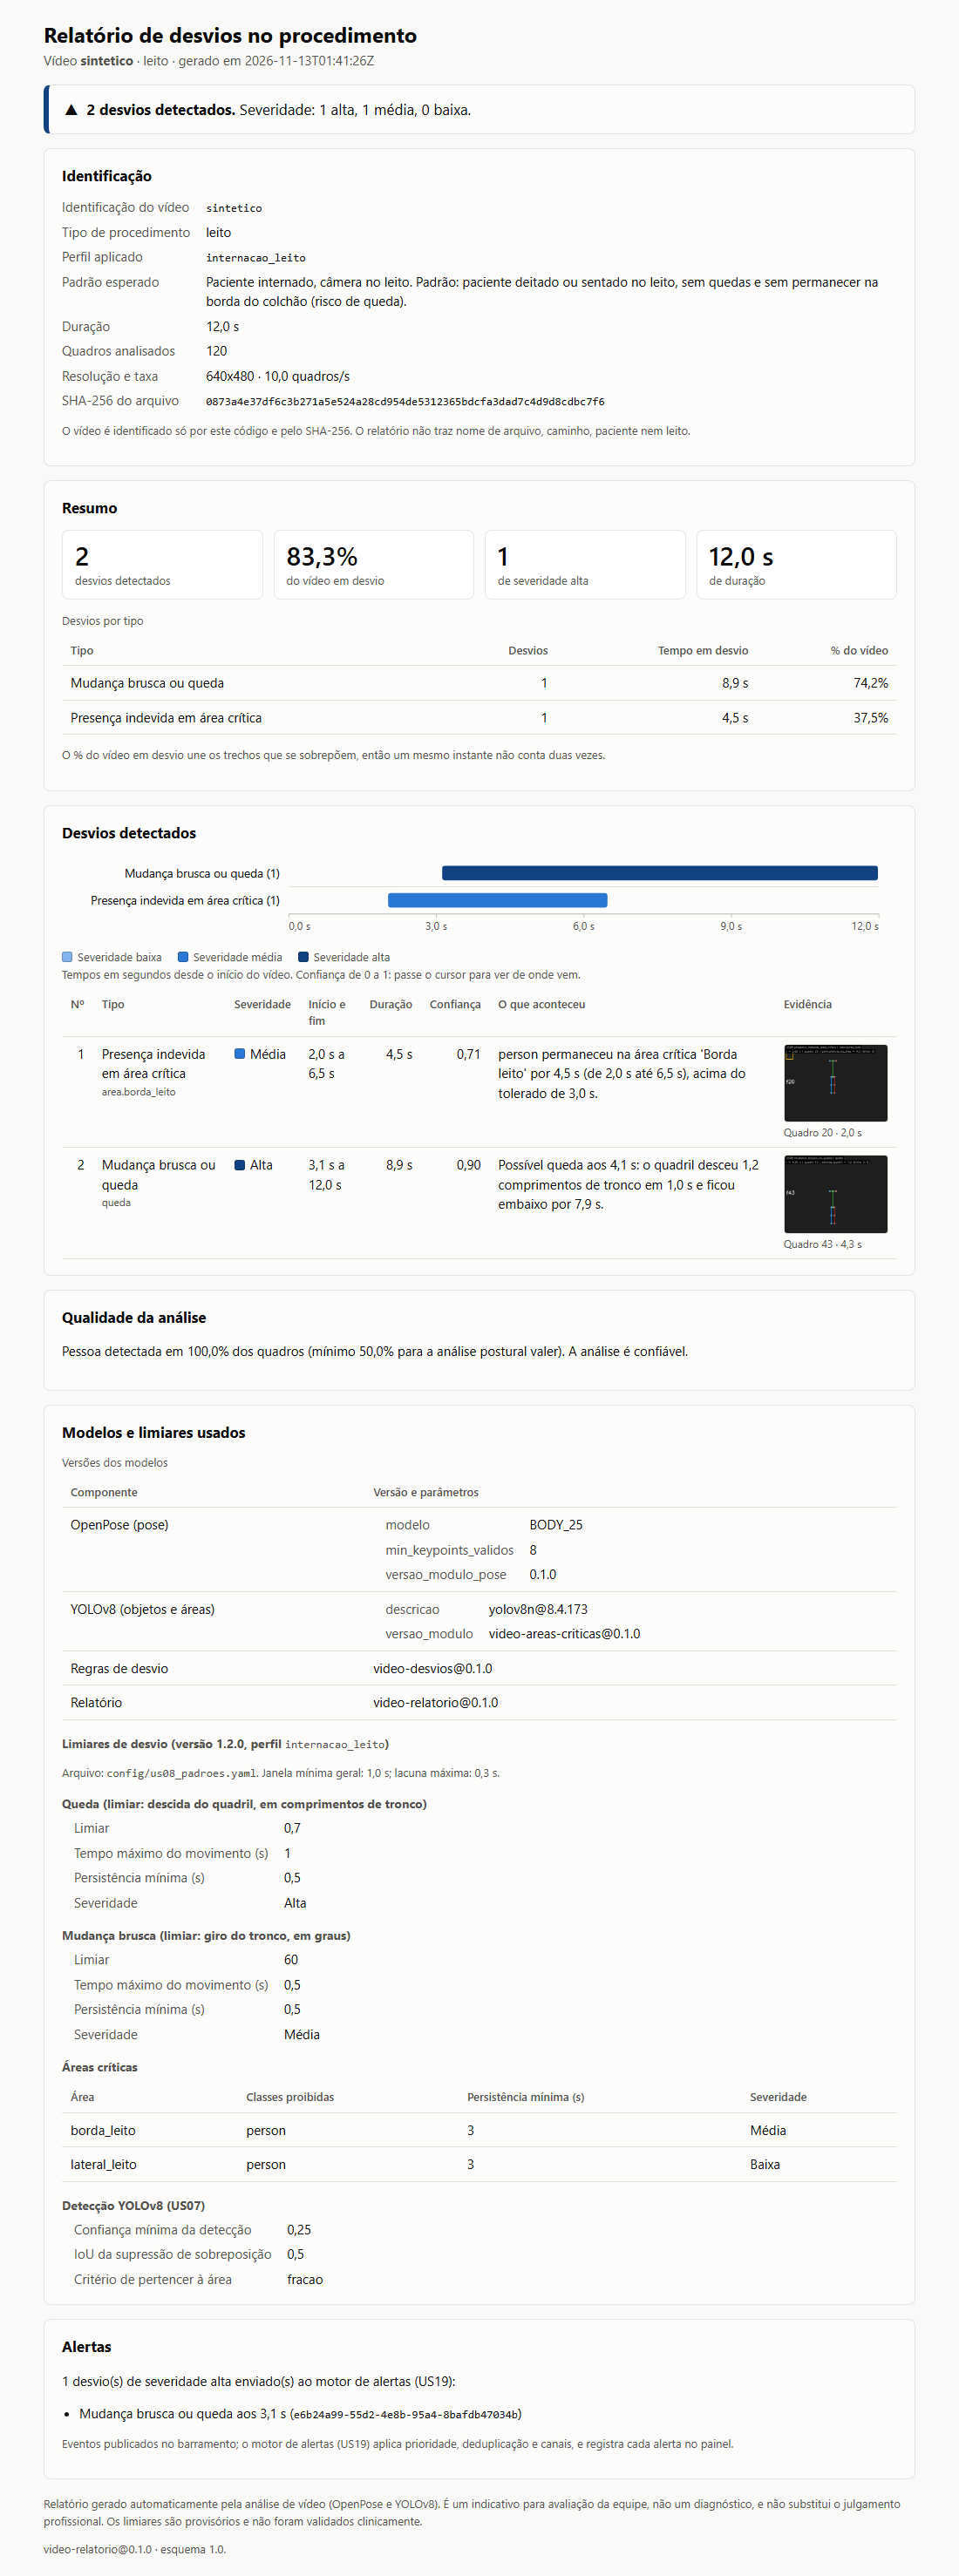

In [21]:
def achar_navegador():
    for nome in ("chrome", "google-chrome", "chromium", "chromium-browser", "msedge", "microsoft-edge"):
        achado = shutil.which(nome)
        if achado:
            return achado
    for caminho in (r"C:\Program Files\Google\Chrome\Application\chrome.exe", r"C:\Program Files (x86)\Google\Chrome\Application\chrome.exe",
                    r"C:\Program Files (x86)\Microsoft\Edge\Application\msedge.exe", r"C:\Program Files\Microsoft\Edge\Application\msedge.exe",
                    "/Applications/Google Chrome.app/Contents/MacOS/Google Chrome", "/usr/bin/google-chrome", "/usr/bin/chromium"):
        if Path(caminho).is_file():
            return caminho
    return None

def capturar(caminho_html, caminho_png, largura=1100):
    navegador = achar_navegador()
    if navegador is None:
        return None
    from PIL import Image as PIL
    destino = (RAIZ / caminho_png).resolve()
    subprocess.run([navegador, "--headless=new", "--disable-gpu", "--hide-scrollbars", f"--window-size={largura},4200",
                    f"--screenshot={destino}", (RAIZ / caminho_html).resolve().as_uri()], capture_output=True, timeout=120)
    if not destino.is_file():
        return None
    imagem = PIL.open(destino).convert("RGB")
    fundo = np.array([249, 249, 247])
    linhas_com_conteudo = np.where((np.abs(np.asarray(imagem).astype(int) - fundo).sum(axis=2) > 12).any(axis=1))[0]
    imagem.crop((0, 0, imagem.width, min(imagem.height, int(linhas_com_conteudo.max()) + 24))).save(destino)   # corta o branco do fim
    return caminho_png

png_principal = capturar(caminho_html, DESTINO / "esboco_com_desvios.png")
if png_principal is None:
    print("Chrome/Edge não encontrado: abra o HTML no navegador:", caminho_html.as_posix())
else:
    print("Esboço 1: relatório de um vídeo COM desvios (queda alta + presença na borda do leito, média)\n")
    display(Imagem(filename=png_principal, width=980))

Esboço 2: relatório de um vídeo SEM desvios (nunca vazio: identifica o vídeo, o padrão, os modelos e os limiares)



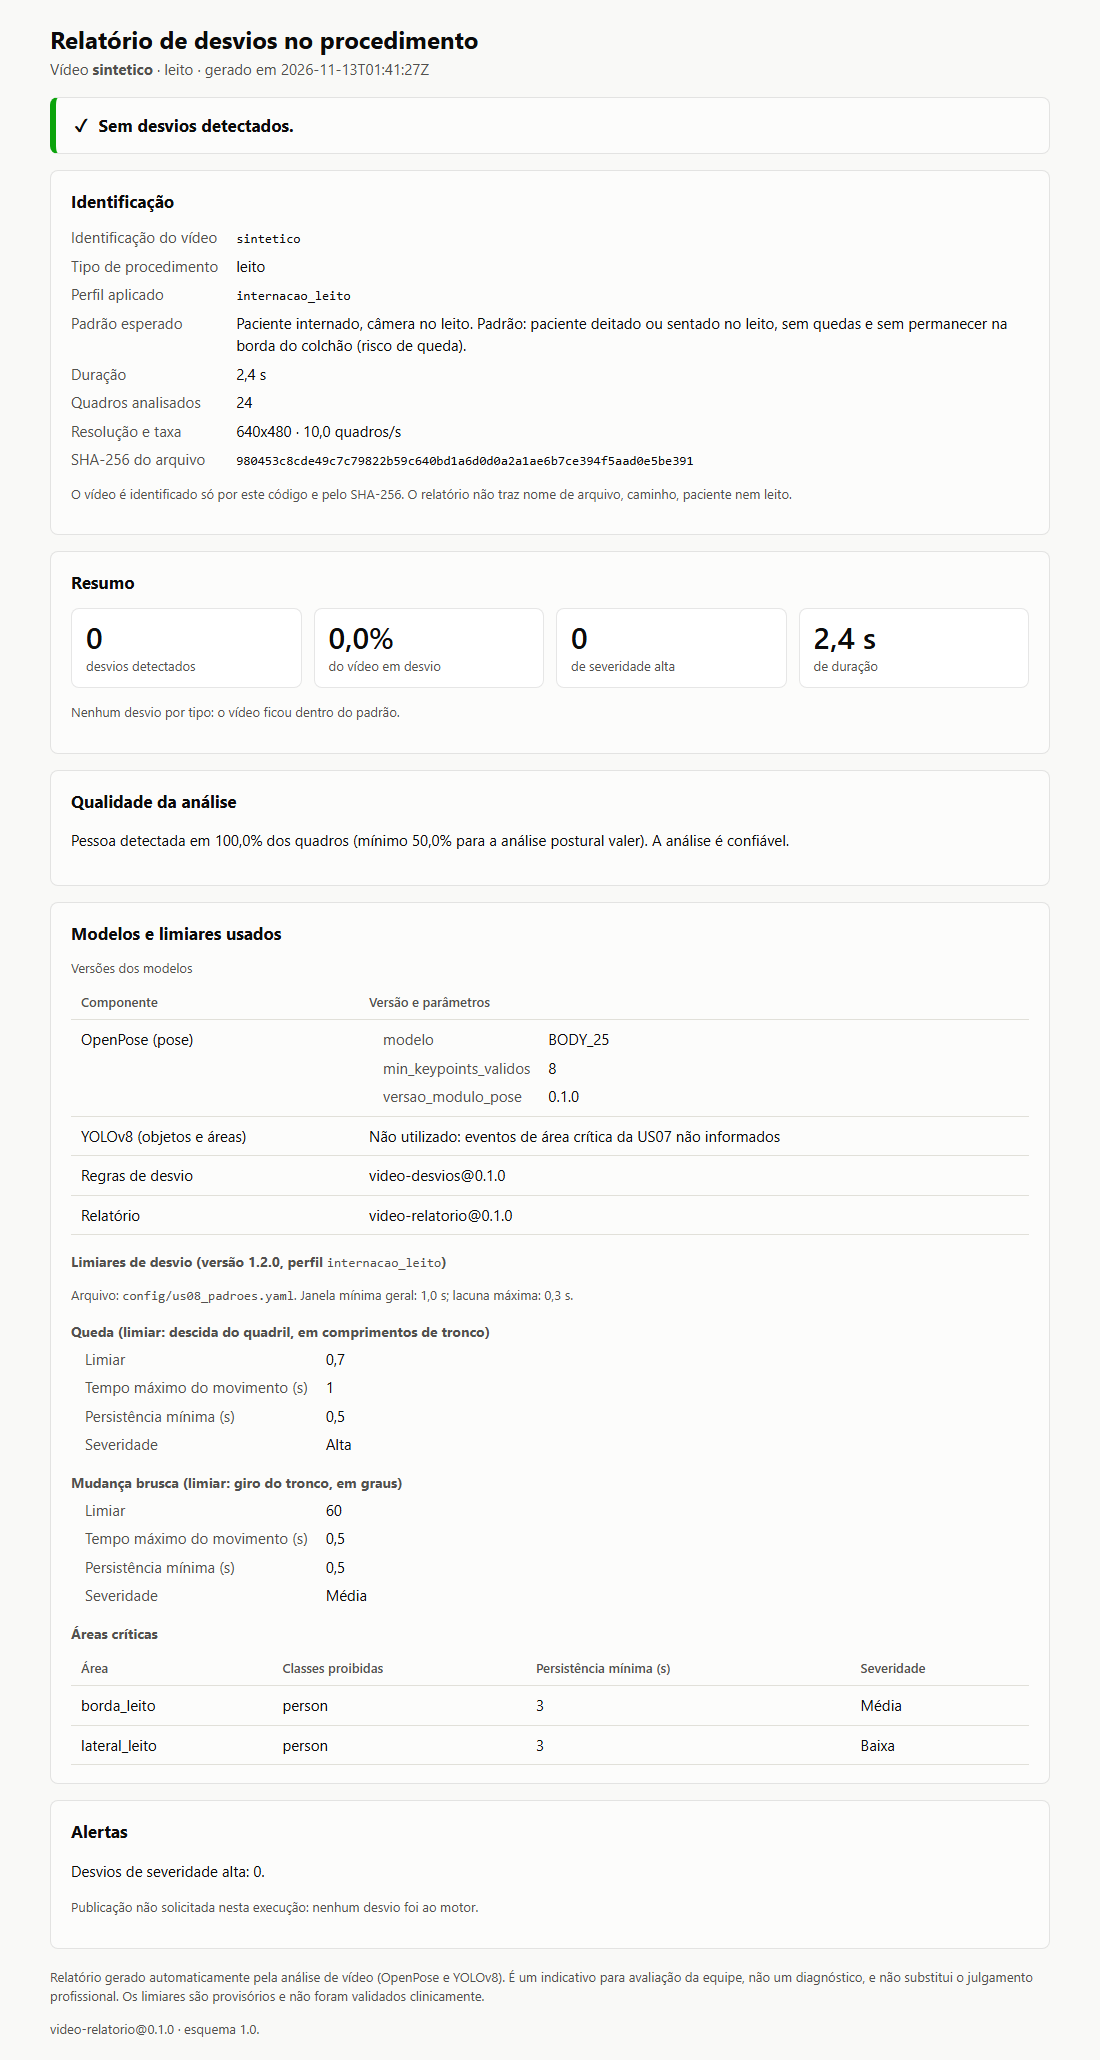

In [22]:
png_sem = capturar(casos["sem_desvios"].caminho_html, DESTINO / "esboco_sem_desvios.png")
if png_sem is None:
    print("Chrome/Edge não encontrado: abra o HTML no navegador:", casos["sem_desvios"].caminho_html.as_posix())
else:
    print("Esboço 2: relatório de um vídeo SEM desvios (nunca vazio: identifica o vídeo, o padrão, os modelos e os limiares)\n")
    display(Imagem(filename=png_sem, width=980))


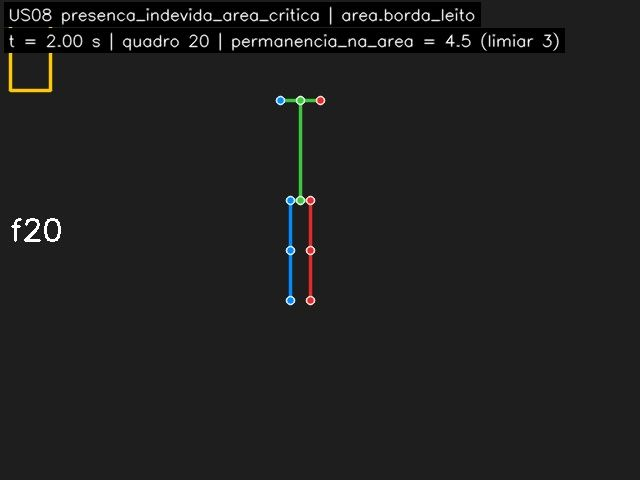
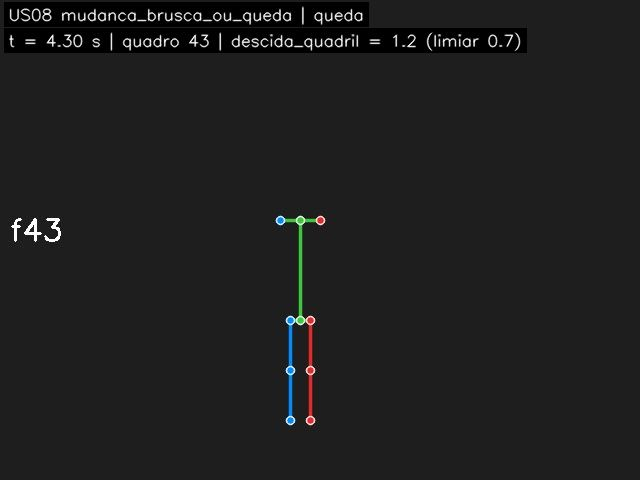

Para abrir no navegador (e imprimir em PDF com Ctrl+P): saida/validacao_us09/20261112-224122/relatorio_etapas.html
Todos os arquivos desta validação: saida/validacao_us09/20261112-224122/


In [23]:
# A mesma página, embutida (isolada em um iframe para o CSS dela não mexer no notebook).
# Alguns visualizadores (GitHub, por exemplo) removem iframes: as imagens acima valem nesses casos.
import warnings

warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")   # o IFrame não aceita o HTML em memória
pagina_final = caminho_html.read_text(encoding="utf-8")
display(HTML(f'<iframe srcdoc="{html.escape(pagina_final, quote=True)}" '
             'style="width:100%;height:1000px;border:1px solid #c3c2b7;border-radius:8px;background:#fff"></iframe>'))
print("Para abrir no navegador (e imprimir em PDF com Ctrl+P):", caminho_html.as_posix())
print("Todos os arquivos desta validação:", DESTINO.as_posix() + "/")